# Systematic Futures Portfolio

A trend-following trading system for **22 futures markets** across stock indices, bonds,
currencies, energy, metals and crops, tested on 2000–2024 with realistic trading costs.

**The idea in one sentence:** buy markets that have been rising, sell markets that have been
falling, and size every position so each market carries the same amount of risk.

This notebook walks through the system one piece at a time, the same order it was built:

1. [Data](#1.-Data) – 22 markets, back-adjusted for contract rolls
2. [Trend signal](#2.-Trend-signal) – moving-average crossovers turned into a forecast
3. [Position sizing](#3.-Position-sizing) – forecast → number of contracts, by risk
4. [Profit, loss and costs](#4.-Profit,-loss-and-costs) – one market end to end
5. [Portfolio](#5.-Portfolio) – all 22 markets together, at \$100k and \$1m
6. [Results](#6.-Results) – against "always long" and the S&P 500
7. [Honesty checks](#7.-Honesty-checks) – sensitivity, luck, and an untouched held-back period
8. [What I learned](#8.-What-I-learned)

All logic lives in the `sfp` package (`src/sfp/`) and is covered by 48 unit tests, including
tests that prove no step uses future prices. This notebook only calls it and shows the results.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sfp.config import load_instruments, load_settings
from sfp.data import load_market, roll_dates
from sfp.signals import SPEEDS, always_long, ewmac, scale_forecast, trend_forecast
from sfp.sizing import ideal_position, yearly_dollar_risk
from sfp.backtest import run_market
from sfp.portfolio import market_weights, run_portfolio, total
from sfp.stats import drawdowns, summary_table, yearly_returns
from sfp.checks import bootstrap_sharpe, yearly_risk

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
INK, SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SECTOR_COLOURS = dict(zip(["equity", "bond", "fx", "energy", "metals", "agriculture"],
                          [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]))

plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 100,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": INK, "axes.labelcolor": SECONDARY, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.5, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]),
})
pd.set_option("display.float_format", "{:,.2f}".format)

settings = load_settings()
instruments = load_instruments()
markets = {code: load_market(i) for code, i in instruments.items()}

CAPITAL = 1_000_000
TEST = slice(settings["start_date"], "2021-03-31")
HOLDOUT = slice(settings["holdout_start"], None)
settings

{'capital_levels': [100000, 1000000],
 'start_date': '2000-01-01',
 'holdout_start': '2021-04-01',
 'target_annual_vol': 0.2,
 'buffer': 0.1,
 'diversification_multiplier': 2.0}

## 1. Data

Free daily data from the [pysystemtrade](https://github.com/robcarver17/pysystemtrade) dataset
(data files only; all code here is my own). It runs to **28 March 2024**.

Six sectors, chosen for liquidity, not for past performance:

In [2]:
universe = pd.DataFrame({
    "market": [i.name for i in instruments.values()],
    "sector": [i.sector for i in instruments.values()],
    "currency": [i.currency for i in instruments.values()],
    "$ per 1.0 price move": [i.multiplier for i in instruments.values()],
    "data from": [markets[c].index[0].date() for c in instruments],
    "contract rolls": [len(roll_dates(markets[c])) for c in instruments],
}, index=list(instruments))
universe

,market,sector,currency,$ per 1.0 price move,data from,contract rolls
SP500,S&P 500,equity,USD,50,1982-09-14,166
NASDAQ,Nasdaq 100,equity,USD,20,1999-12-14,97
EUROSTX,Euro Stoxx 50,equity,EUR,10,2014-03-13,40
NIKKEI,Nikkei 225,equity,JPY,100,2011-06-10,135
FTSE100,FTSE 100,equity,GBP,10,1984-05-21,159
US10,US 10y Note,bond,USD,1000,1982-08-30,166
US30,US Ultra Bond,bond,USD,1000,2010-03-03,56
BUND,German Bund,bond,EUR,1000,2006-12-01,69
GILT,UK Gilt,bond,GBP,1000,1983-03-25,164
EUR,EUR/USD,fx,USD,125000,1999-06-15,99


### Why two prices per market?

Futures contracts expire, so every few months the system sells the old contract and buys the
next one (a **roll**). The two contracts trade at slightly different prices, so joining their
prices together creates fake jumps.

- The **back-adjusted price** shifts history so the joins are smooth. Its *changes* are real,
  so it drives the signal and the profit. Its *level* drifts away from reality (it even goes
  negative for crude oil), so it is never used for percentage returns.
- The **contract price** is what was actually traded, so it is used when the real level matters.

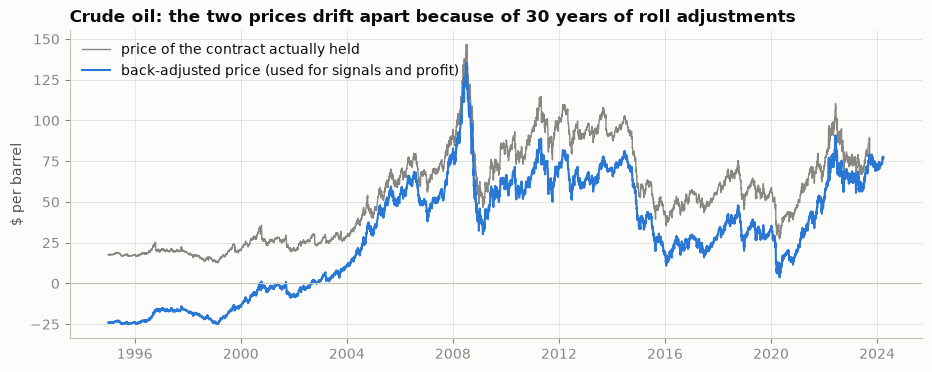

In [3]:
oil = markets["CRUDE_W"]["1995":]
fig, ax = plt.subplots()
ax.plot(oil["price"], color=MUTED, linewidth=1, label="price of the contract actually held")
ax.plot(oil["adjusted"], color=BLUE, label="back-adjusted price (used for signals and profit)")
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.set_title("Crude oil: the two prices drift apart because of 30 years of roll adjustments")
ax.set_ylabel("$ per barrel")
ax.legend(loc="upper left")
plt.show()

## 2. Trend signal

A **moving average** smooths out daily noise. Comparing a fast one with a slow one shows the
trend: if the fast average is above the slow one, prices have been rising, so **buy**; below, **sell**.

The gap is divided by the market's typical daily move so that a "big" gap means the same thing
in oil, gold or the yen. Then it is rescaled so the average size is 10 and capped at ±20,
using **only data available at the time**.

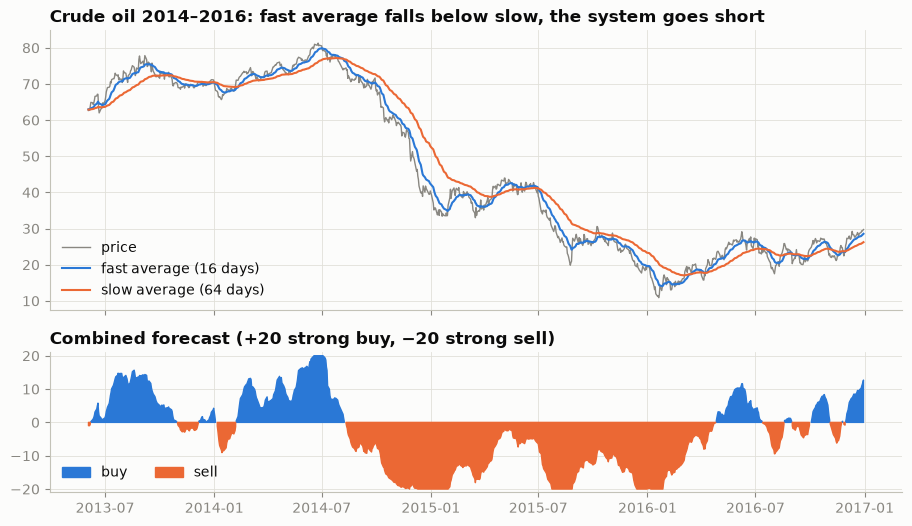

In [4]:
prices = markets["CRUDE_W"]["adjusted"]
forecast = trend_forecast(prices)
window = slice("2013-06", "2016-12")

fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(11, 6), height_ratios=[2, 1])
top.plot(prices[window], color=MUTED, linewidth=1, label="price")
top.plot(prices.ewm(span=16).mean()[window], color=BLUE, label="fast average (16 days)")
top.plot(prices.ewm(span=64).mean()[window], color=ORANGE, label="slow average (64 days)")
top.set_title("Crude oil 2014–2016: fast average falls below slow, the system goes short")
top.legend(loc="lower left")

f = forecast[window]
bottom.fill_between(f.index, f, 0, where=f > 0, color=BLUE, label="buy")
bottom.fill_between(f.index, f, 0, where=f < 0, color=ORANGE, label="sell")
bottom.set_ylim(-21, 21)
bottom.set_title("Combined forecast (+20 strong buy, −20 strong sell)")
bottom.legend(loc="lower left", ncol=2)
plt.show()

### Four speeds instead of one

One crossover is either fast (quick to react, fooled by noise) or slow (steady, late). The
system averages four: 8/32, 16/64, 32/128 and 64/256 days. They agree on the big trends but
differ enough that combining them gives a steadier forecast:

In [5]:
by_speed = pd.DataFrame({
    f"{fast}/{slow}": scale_forecast(ewmac(prices, fast, slow)) for fast, slow in SPEEDS
})
print("Correlation between the four speeds on crude oil:")
by_speed.corr()

Correlation between the four speeds on crude oil:


,8/32,16/64,32/128,64/256
8/32,1.00,0.89,0.63,0.35
16/64,0.89,1.00,0.88,0.58
32/128,0.63,0.88,1.00,0.86
64/256,0.35,0.58,0.86,1.00


## 3. Position sizing

The forecast says *how confident* the system is, not *how much* to buy. One crude oil contract
swings about ten times more in dollars than one corn contract, so buying one of each would let
oil dominate. Instead every position is sized by **risk**:

$$
\text{contracts} = \frac{\text{forecast}}{10} \times
\frac{\text{capital} \times 20\% \times \text{weight}}
     {\text{yearly dollar risk of one contract}}
$$

where yearly dollar risk = typical daily price move × multiplier × FX rate × 16
(√256 trading days). When a market gets wilder, each contract is riskier, so the system
**automatically holds fewer**.

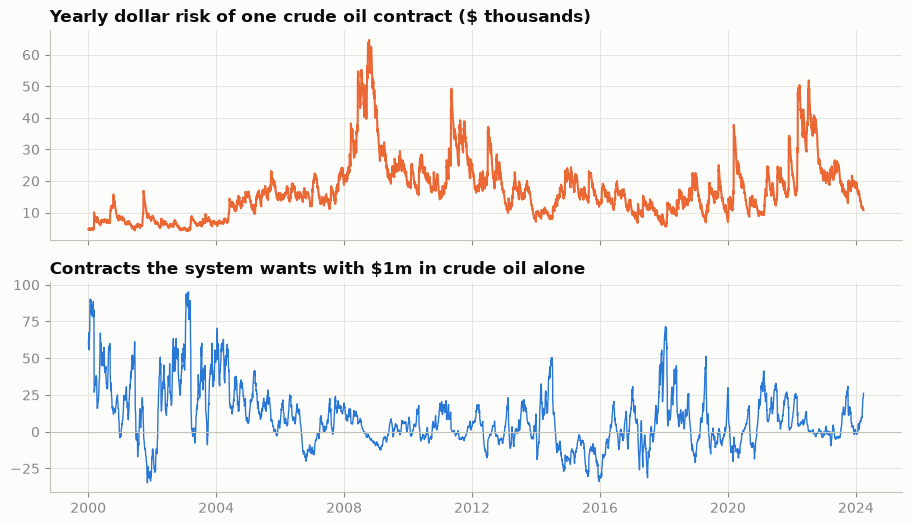

2005-06-01: forecast   7.8, risk per contract $ 15,356  →   10.2 contracts
2008-07-01: forecast  18.2, risk per contract $ 44,942  →    8.1 contracts


In [6]:
crude = instruments["CRUDE_W"]
risk = yearly_dollar_risk(prices, crude, markets["CRUDE_W"]["fx"])
ideal = ideal_position(forecast, risk, CAPITAL, settings["target_annual_vol"])

fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(11, 6))
top.plot(risk["2000":] / 1000, color=ORANGE)
top.set_title("Yearly dollar risk of one crude oil contract ($ thousands)")
bottom.plot(ideal["2000":], color=BLUE, linewidth=1)
bottom.axhline(0, color="#c3c2b7", linewidth=0.8)
bottom.set_title("Contracts the system wants with $1m in crude oil alone")
plt.show()

for day in ["2005-06-01", "2008-07-01"]:
    print(f"{day}: forecast {forecast[day]:5.1f}, risk per contract ${risk[day]:>7,.0f}  →  {ideal[day]:5.1f} contracts")

In mid-2008 the forecast was more than twice as strong as in 2005, yet the system held *fewer*
contracts, because each contract was three times as risky. Nobody had to decide to "be careful"
in a wild market — the formula does it.

## 4. Profit, loss and costs

**Profit** each day = *yesterday's* position × today's price change × multiplier × FX rate.
Using yesterday's position is what stops the backtest cheating: a decision made at today's close
can only earn tomorrow's move.

**Costs** = contracts traded × (commission + half the bid-ask spread). On a roll day the whole
position is sold and bought again, so that counts double. A small **buffer** skips trades when
the ideal position has only moved a little.

In [7]:
crude_runs = {
    "before costs": run_market(markets["CRUDE_W"], crude, CAPITAL, settings, use_buffer=False)["gross_pnl"],
    "after costs, no buffer": run_market(markets["CRUDE_W"], crude, CAPITAL, settings, use_buffer=False)["pnl"],
    "after costs, with buffer": run_market(markets["CRUDE_W"], crude, CAPITAL, settings)["pnl"],
}
crude_returns = {name: (pnl / CAPITAL)[TEST] for name, pnl in crude_runs.items()}
print("Crude oil on its own, $1m, 2000 – March 2021")
summary_table(crude_returns).T

Crude oil on its own, $1m, 2000 – March 2021


,yearly return,yearly risk,Sharpe,worst drawdown,monthly skew
before costs,0.13,0.25,0.54,-0.78,0.87
"after costs, no buffer",0.13,0.25,0.52,-0.80,0.86
"after costs, with buffer",0.12,0.25,0.50,-0.80,0.80


Trend following trades slowly (positions last weeks to months), so costs only take about 0.5%
a year here. The buffer cuts trading costs by a third but reacts slightly later, so on oil it
roughly breaks even — a reminder that sensible-sounding ideas still need measuring.

## 5. Portfolio

All 22 markets run together. Risk is split **equally across the six sectors**, then equally
across the markets in each sector that have started trading. Markets that start later (Euro
Stoxx in 2014, for example) join when their data begins:

In [8]:
forecasts = pd.DataFrame({c: trend_forecast(m["adjusted"]) for c, m in markets.items()})
weights = market_weights(forecasts, instruments)
sectors = pd.Series({c: i.sector for c, i in instruments.items()})
pd.DataFrame({
    "sector": sectors,
    "% of risk in 2005": weights.loc["2005-06-01"] * 100,
    "% of risk in 2020": weights.loc["2020-06-01"] * 100,
}).sort_values(["sector", "% of risk in 2020"]).round(1)

,sector,% of risk in 2005,% of risk in 2020
CORN,agriculture,5.60,5.60
SOYBEAN,agriculture,5.60,5.60
WHEAT,agriculture,5.60,5.60
US10,bond,8.30,4.20
US30,bond,0.00,4.20
BUND,bond,0.00,4.20
GILT,bond,8.30,4.20
CRUDE_W,energy,8.30,8.30
GAS_US,energy,8.30,8.30
SP500,equity,5.60,3.30


Because markets partly cancel each other out, 22 small bets swing far less than one big one. A
**diversification multiplier** of 2.0 scales positions back up towards the 20% risk target.

The whole system then runs at two account sizes:

In [9]:
trend = {cap: run_portfolio(markets, instruments, cap, settings) for cap in settings["capital_levels"]}
trend_returns = {cap: (total(r, "pnl") / cap)[TEST] for cap, r in trend.items()}

rows = {}
for cap, results in trend.items():
    held = pd.DataFrame({c: r["position"] for c, r in results.items()})[TEST]
    stats = summary_table({cap: trend_returns[cap]})[cap]
    rows[f"${cap:,}"] = {
        "yearly return": f"{stats['yearly return']:.1%}",
        "yearly risk (target 20%)": f"{stats['yearly risk']:.1%}",
        "Sharpe": f"{stats['Sharpe']:.2f}",
        "markets held on a typical day": f"{(held != 0).sum(axis=1).mean():.1f} of 22",
    }
pd.DataFrame(rows)

,"$100,000","$1,000,000"
yearly return,4.5%,11.2%
yearly risk (target 20%),11.0%,17.5%
Sharpe,0.41,0.64
markets held on a typical day,6.6 of 22,18.6 of 22


### Why \$100k isn't enough

You can't hold part of a contract. With \$100k, most markets' ideal position is well under one
contract, and anything below 0.5 rounds to **zero**, so those markets are never traded:

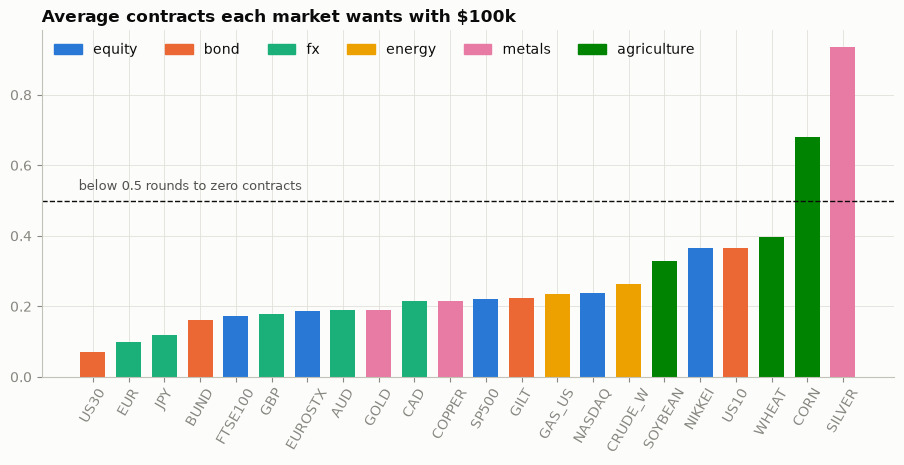

In [10]:
held_1m = pd.DataFrame({c: r["position"] for c, r in trend[1_000_000].items()})[TEST]
wanted_100k = (held_1m.abs().mean() / 10).sort_values()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(wanted_100k.index, wanted_100k, color=[SECTOR_COLOURS[sectors[c]] for c in wanted_100k.index], width=0.7)
ax.axhline(0.5, color=INK, linewidth=1, linestyle="--")
ax.text(-0.4, 0.53, "below 0.5 rounds to zero contracts", color=SECONDARY, fontsize=9)
ax.set_title("Average contracts each market wants with $100k")
ax.tick_params(axis="x", rotation=60)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SECTOR_COLOURS.values()]
ax.legend(handles, SECTOR_COLOURS.keys(), ncol=6, loc="upper left")
plt.show()

## 6. Results

The \$1m trend portfolio compared with two simple alternatives, over 2000 – March 2021:

- **Always long** – same 22 markets, same sizing, but always buying. Shows what the trend
  *signal* adds on top of simply owning a diversified basket.
- **S&P 500 buy and hold** – the classic "just own stocks" benchmark (futures return, so
  excluding dividends and interest).

In [11]:
long_only = run_portfolio(markets, instruments, CAPITAL, settings, signal=always_long)
sp = markets["SP500"]
sp500 = (sp["adjusted"].diff() / sp["price"].shift(1))[TEST].fillna(0)

main = trend_returns[CAPITAL]
compare = {
    "trend $1m": main,
    "trend $1m before costs": (total(trend[CAPITAL], "gross_pnl") / CAPITAL)[TEST],
    "trend $100k": trend_returns[100_000],
    "always long $1m": (total(long_only, "pnl") / CAPITAL)[TEST],
    "S&P 500 buy and hold": sp500,
}
summary_table(compare).T

,yearly return,yearly risk,Sharpe,worst drawdown,monthly skew
trend $1m,0.11,0.17,0.64,-0.40,0.34
trend $1m before costs,0.12,0.17,0.70,-0.36,0.34
trend $100k,0.04,0.11,0.41,-0.26,0.83
always long $1m,0.08,0.15,0.55,-0.63,-0.28
S&P 500 buy and hold,0.06,0.19,0.32,-0.77,-0.47


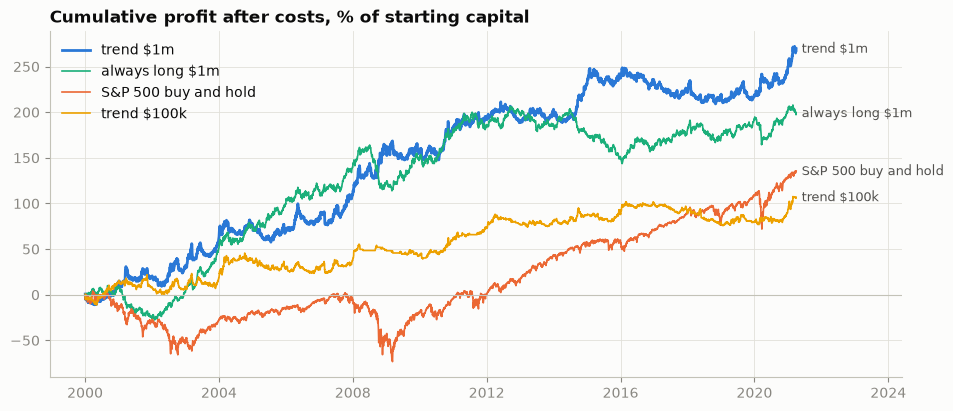

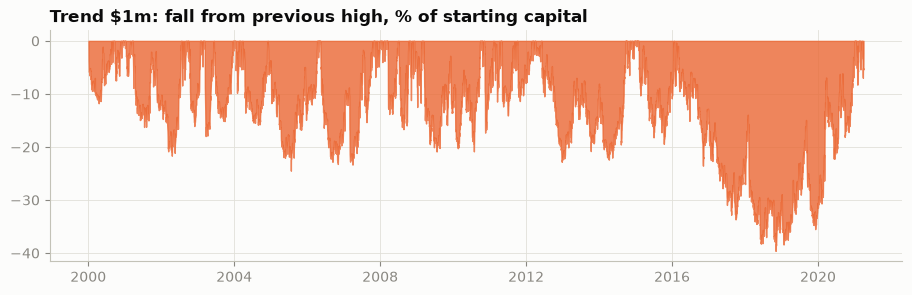

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.5))
colours = {"trend $1m": BLUE, "always long $1m": AQUA, "S&P 500 buy and hold": ORANGE, "trend $100k": YELLOW}
for name, colour in colours.items():
    curve = compare[name].cumsum() * 100
    ax.plot(curve, color=colour, linewidth=2 if name == "trend $1m" else 1.2, label=name)
    ax.annotate(name, (curve.index[-1], curve.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                color=SECONDARY, fontsize=9, va="center")
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.set_title("Cumulative profit after costs, % of starting capital")
ax.set_xlim(right=pd.Timestamp("2024-06-01"))
ax.legend(loc="upper left")
plt.show()

fig, ax = plt.subplots(figsize=(11, 3))
dd = drawdowns(main) * 100
ax.fill_between(dd.index, dd, 0, color=ORANGE, alpha=0.8)
ax.set_title("Trend $1m: fall from previous high, % of starting capital")
plt.show()

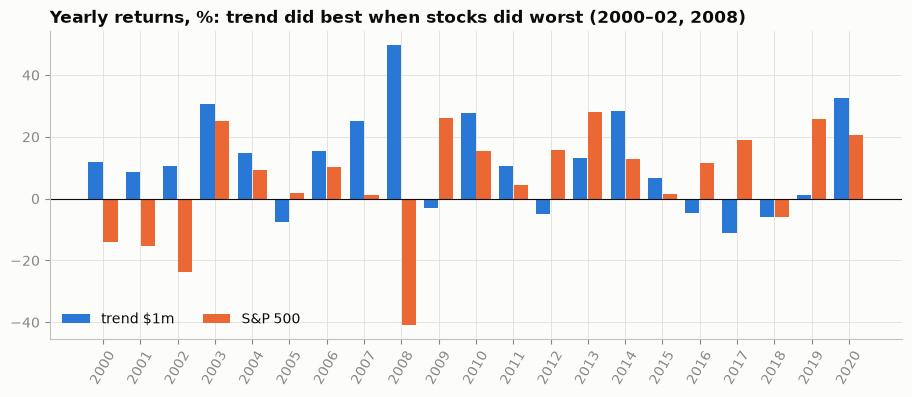

In [13]:
yearly = pd.DataFrame({"trend $1m": yearly_returns(main), "S&P 500": yearly_returns(sp500)}) * 100
yearly = yearly.drop(2021)

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(yearly))
ax.bar(x - 0.2, yearly["trend $1m"], width=0.38, color=BLUE, label="trend $1m")
ax.bar(x + 0.2, yearly["S&P 500"], width=0.38, color=ORANGE, label="S&P 500")
ax.set_xticks(x, yearly.index, rotation=60)
ax.axhline(0, color=INK, linewidth=0.8)
ax.set_title("Yearly returns, %: trend did best when stocks did worst (2000–02, 2008)")
ax.legend(loc="lower left", ncol=2)
plt.show()

### Protection when stocks fall

Each dot is one month. Trend following tends to make money in the months stocks fall hardest,
because big sell-offs are themselves trends. This is the main reason investors hold it
alongside shares.

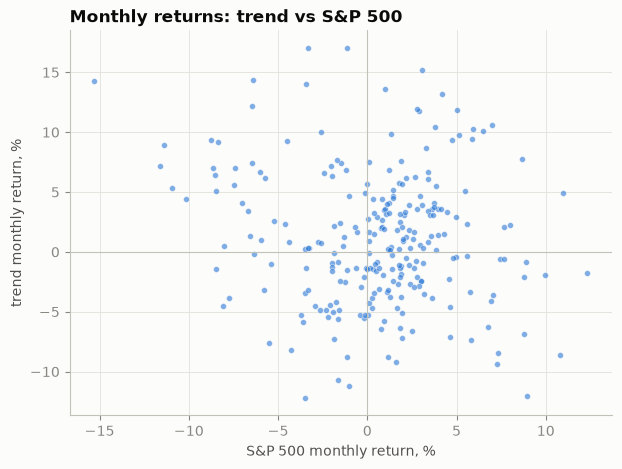

Correlation with the S&P 500: -0.15
In months the S&P 500 fell: trend made +1.2% on average, the S&P 500 -3.9%


In [14]:
monthly = pd.DataFrame({"trend": main, "sp500": sp500}).resample("ME").sum() * 100
down = monthly[monthly["sp500"] < 0]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(monthly["sp500"], monthly["trend"], s=18, color=BLUE, alpha=0.6, edgecolor=SURFACE, linewidth=0.5)
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.axvline(0, color="#c3c2b7", linewidth=0.8)
ax.set_xlabel("S&P 500 monthly return, %")
ax.set_ylabel("trend monthly return, %")
ax.set_title("Monthly returns: trend vs S&P 500")
plt.show()

print(f"Correlation with the S&P 500: {monthly.corr().iloc[0, 1]:.2f}")
print(f"In months the S&P 500 fell: trend made {down['trend'].mean():+.1f}% on average, the S&P 500 {down['sp500'].mean():+.1f}%")

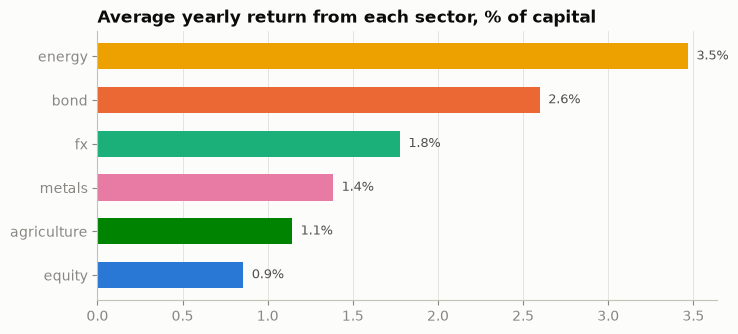

In [15]:
by_market = pd.DataFrame({c: r["pnl"] for c, r in trend[CAPITAL].items()})[TEST].fillna(0)
years = len(main) / 256
by_sector = (by_market.T.groupby(sectors).sum().T.sum() / CAPITAL / years * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(by_sector.index, by_sector, color=[SECTOR_COLOURS[s] for s in by_sector.index], height=0.6)
for y, value in enumerate(by_sector):
    ax.text(value + 0.05, y, f"{value:.1f}%", va="center", color=SECONDARY, fontsize=9)
ax.set_title("Average yearly return from each sector, % of capital")
ax.grid(axis="y", visible=False)
plt.show()

**Takeaways**

- **Sharpe 0.64 after costs**, close to what real trend-following funds achieved over this period.
- **Positive skew**: many small losses and a few large wins, the mirror image of owning stocks.
- The trend signal beats "always long" mainly on **drawdown** (−40% vs −63%) and after 2014, when
  simply owning things stopped working.
- The hard part is the **2016–2019 drawdown**: four flat-to-losing years that would test anyone's
  patience in real life.

## 7. Honesty checks

A good backtest is easy to fool yourself with. Four checks:

### 7a. Change one thing at a time
If the result only works with one exact setting, it was probably luck.

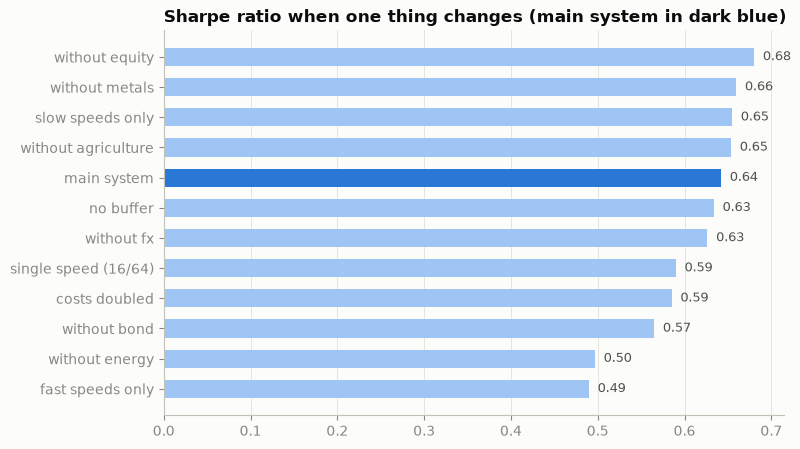

In [16]:
from dataclasses import replace

def run_variant(signal=trend_forecast, use_buffer=True, chosen=instruments):
    picked = {c: markets[c] for c in chosen}
    return (total(run_portfolio(picked, chosen, CAPITAL, settings, signal, use_buffer), "pnl") / CAPITAL)[TEST]

variants = {
    "main system": main,
    "fast speeds only": run_variant(lambda p: trend_forecast(p, [(8, 32), (16, 64)])),
    "slow speeds only": run_variant(lambda p: trend_forecast(p, [(32, 128), (64, 256)])),
    "single speed (16/64)": run_variant(lambda p: trend_forecast(p, [(16, 64)])),
    "no buffer": run_variant(use_buffer=False),
    "costs doubled": run_variant(chosen={c: replace(i, commission=i.commission * 2, spread=i.spread * 2)
                                         for c, i in instruments.items()}),
}
for sector in SECTOR_COLOURS:
    variants[f"without {sector}"] = run_variant(chosen={c: i for c, i in instruments.items() if i.sector != sector})

sharpes = summary_table(variants).T["Sharpe"].sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(sharpes.index, sharpes, color=[BLUE if n == "main system" else "#9ec5f4" for n in sharpes.index], height=0.6)
for y, value in enumerate(sharpes):
    ax.text(value + 0.01, y, f"{value:.2f}", va="center", color=SECONDARY, fontsize=9)
ax.set_title("Sharpe ratio when one thing changes (main system in dark blue)")
ax.grid(axis="y", visible=False)
plt.show()

Every variant stays between about 0.5 and 0.7, so the result isn't balanced on one lucky
setting. Two honest weaknesses show up: **fast signals are worse** (they chase noise), and
**energy carries more of the result than it should**.

### 7b. Could it be luck?
Rebuild the history 1,000 times by picking random months, and see what range of Sharpe ratios
comes out.

In [17]:
low, middle, high = bootstrap_sharpe(main)
risk_by_year = yearly_risk(main)
print(f"90% of reshuffled histories have a Sharpe between {low:.2f} and {high:.2f} (middle {middle:.2f})")
print(f"Actual risk: average {risk_by_year.mean():.0%} a year against a 20% target "
      f"(lowest {risk_by_year.min():.0%} in {risk_by_year.idxmin()}, highest {risk_by_year.max():.0%} in {risk_by_year.idxmax()})")

90% of reshuffled histories have a Sharpe between 0.32 and 0.96 (middle 0.64)
Actual risk: average 18% a year against a 20% target (lowest 12% in 2013, highest 27% in 2008)


Even the unlucky end of the range is above zero, so the edge is probably real, though 21 years
isn't enough to pin down its exact size.

### 7c. The held-back test

Everything from **April 2021 to March 2024** was kept aside while building the system and run
**once**, at the very end. Nothing was tuned after seeing it.

,yearly return,yearly risk,Sharpe,worst drawdown,monthly skew
2000 – Mar 2021 (built on),0.11,0.17,0.64,-0.40,0.34
Apr 2021 – Mar 2024 (held back),0.05,0.16,0.30,-0.35,0.51


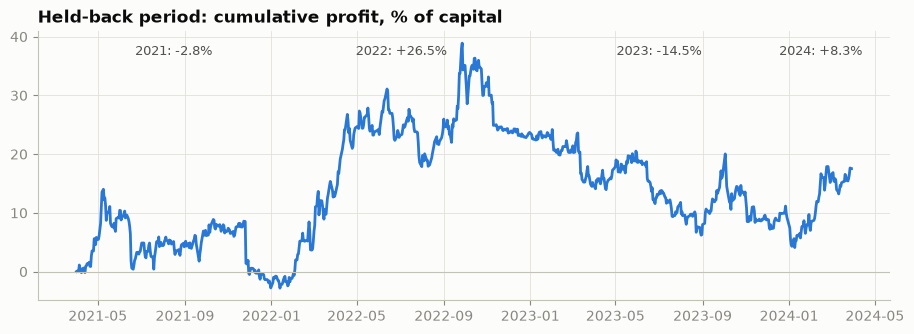

In [18]:
full = total(trend[CAPITAL], "pnl") / CAPITAL
held_back = full[HOLDOUT]
display(summary_table({"2000 – Mar 2021 (built on)": main, "Apr 2021 – Mar 2024 (held back)": held_back}).T)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(held_back.cumsum() * 100, color=BLUE, linewidth=2)
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
for year, value in yearly_returns(held_back).items():
    days = held_back.index[held_back.index.year == year]
    middle_day = days[0] + (days[-1] - days[0]) / 2
    ax.text(middle_day, ax.get_ylim()[1] * 0.9, f"{year}: {value:+.1%}",
            ha="center", color=SECONDARY, fontsize=9)
ax.set_title("Held-back period: cumulative profit, % of capital")
plt.show()

The held-back Sharpe of about **0.3** is half the earlier figure, but still positive and inside
the range luck allows for three years. It matches what happened to real trend followers: a
great 2022 (inflation drove long, clean trends) and a painful 2023 (those trends reversed).

## 8. What I learned

**Engineering**
- **Look-ahead bias is the easiest way to fake a good backtest.** Every stage has a test that
  changes future prices and checks past results don't move.
- **The bugs that matter are quiet ones.** Holiday gaps made sector weights jump for one day
  and back, creating thousands of pointless trades. Costs looked like 2.5% a year; after the fix
  they were 1.0% and the Sharpe ratio went from 0.50 to 0.64. It was found by noticing a number
  that didn't fit and breaking it down by market.
- **Build in working pieces.** Each feature (data → signal → sizing → P&L → costs → portfolio →
  report → checks) ran and was tested before the next one started.

**Trading**
- Sizing by risk, not by number of contracts, is what makes a multi-market portfolio work.
- Account size matters: with full-size contracts this needs roughly \$1m.
- A held-back period gives an honest number, and it's usually lower.

**Limitations and next steps**
- Data ends March 2024; the diversification multiplier is fixed at 2.0 rather than estimated.
- Returns are simple (not compounded) and ignore interest on unused cash.
- Next: a **carry** signal, **micro contracts** for small accounts, and newer data.